In [ ]:
#daily data
# 1. IMPORT LIBRARIES
# ==============================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error


C:\Users\ASUS\AppData\Local\Temp\ipykernel_15200\1411701756.py:4: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


In [ ]:
# 2. LOAD DATA
# ==============================
df = pd.read_csv("../delhi-aqi-prediction-using-ml/data/delhi_unprocessed.csv")

df["datetime"] = pd.to_datetime(df["datetime"])
df = df.sort_values("datetime")

In [ ]:
# 3. HANDLE MISSING + HOURLY FIX
# ==============================
df = df.set_index("datetime").resample("H").mean()
df = df.interpolate()
df = df.reset_index()

C:\Users\ASUS\AppData\Local\Temp\ipykernel_15200\3897943592.py:3: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  df = df.set_index("datetime").resample("H").mean()


In [ ]:
# 4. CONVERT TO DAILY
# ==============================
df_daily = df.resample("D", on="datetime").agg({
    "pm25": "mean",
    "pm10": "mean",
    "no2": "mean",
    "so2": "mean",
    "co": "mean",
    "o3": "mean",
    "aqi": "mean"
}).reset_index()

df_daily = df_daily.interpolate()

In [ ]:
# 5. FEATURE ENGINEERING
# ==============================
df_daily["day"] = df_daily["datetime"].dt.day
df_daily["month"] = df_daily["datetime"].dt.month
df_daily["dayofweek"] = df_daily["datetime"].dt.dayofweek
df_daily["is_weekend"] = df_daily["dayofweek"].apply(lambda x: 1 if x >= 5 else 0)

# Lag + rolling (important)
df_daily["aqi_lag1"] = df_daily["aqi"].shift(1)
df_daily["aqi_lag7"] = df_daily["aqi"].shift(7)
df_daily["aqi_roll7"] = df_daily["aqi"].rolling(7).mean()

df_daily = df_daily.dropna()

In [ ]:
# 6. TRAIN TEST SPLIT (TIME BASED)
# ==============================
train = df_daily[df_daily["datetime"] < "2022-01-01"]
test = df_daily[df_daily["datetime"] >= "2022-01-01"]

X_train = train.drop(["aqi", "datetime"], axis=1)
y_train = train["aqi"]

X_test = test.drop(["aqi", "datetime"], axis=1)
y_test = test["aqi"]

In [ ]:
# 7. LINEAR REGRESSION (NO SCALING)
# ==============================
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)



In [ ]:
# 8. RANDOM FOREST (NO SCALING)
# ==============================
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

In [ ]:
# 9. SVR (WITH SCALING)
# ==============================
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

svr = SVR(kernel='rbf', C=100, gamma=0.1, epsilon=0.1)
svr.fit(X_train_scaled, y_train)
y_pred_svr = svr.predict(X_test_scaled)

In [ ]:
# 10. EVALUATION FUNCTION
# ==============================
def evaluate(y_true, y_pred):
    return [
        r2_score(y_true, y_pred),
        mean_absolute_error(y_true, y_pred),
        np.sqrt(mean_squared_error(y_true, y_pred))
    ]

In [ ]:

# 11. MODEL COMPARISON TABLE
# ==============================
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest", "SVR"],
    "R2": [
        evaluate(y_test, y_pred_lr)[0],
        evaluate(y_test, y_pred_rf)[0],
        evaluate(y_test, y_pred_svr)[0]
    ],
    "MAE": [
        evaluate(y_test, y_pred_lr)[1],
        evaluate(y_test, y_pred_rf)[1],
        evaluate(y_test, y_pred_svr)[1]
    ],
    "RMSE": [
        evaluate(y_test, y_pred_lr)[2],
        evaluate(y_test, y_pred_rf)[2],
        evaluate(y_test, y_pred_svr)[2]
    ]
})

results = results.round(2).sort_values(by="R2", ascending=False)

print("\nModel Comparison:\n")
print(results.to_string(index=False))



Model Comparison:

            Model   R2   MAE  RMSE
    Random Forest 1.00  3.16  5.48
              SVR 1.00  3.78  6.19
Linear Regression 0.98 18.54 26.00

Model Comparison:

            Model   R2   MAE  RMSE
    Random Forest 1.00  3.16  5.48
              SVR 1.00  3.78  6.19
Linear Regression 0.98 18.54 26.00


In [ ]:
# 12. FEATURE IMPORTANCE (RF)
# ==============================
feat_imp = pd.Series(rf.feature_importances_, index=X_train.columns)
print("\nFeature Importance:\n")
print(feat_imp.sort_values(ascending=False))


Feature Importance:

pm25          0.790183
aqi_lag1      0.140377
pm10          0.036498
co            0.008374
aqi_roll7     0.007096
o3            0.004455
no2           0.004091
so2           0.002987
aqi_lag7      0.002121
day           0.001622
month         0.001128
dayofweek     0.000902
is_weekend    0.000166
dtype: float64


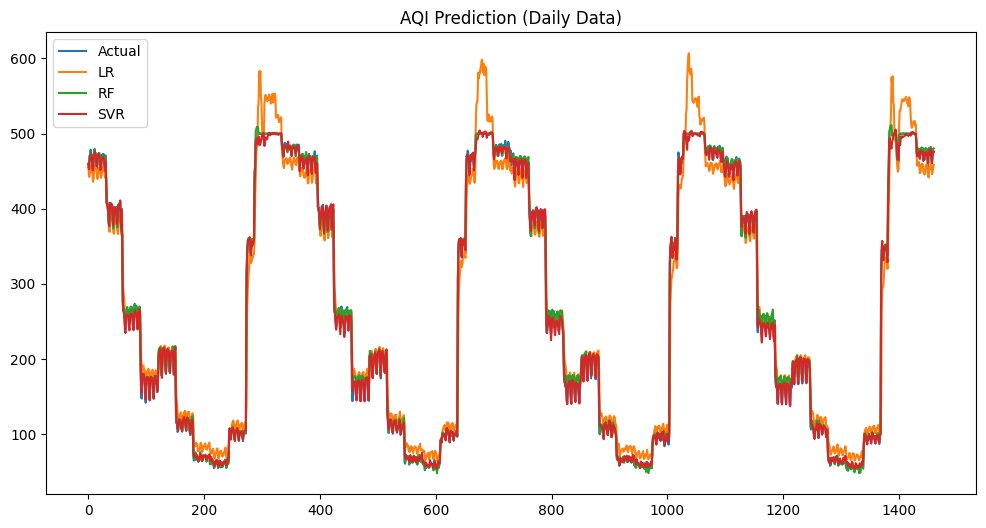

In [ ]:
# 13. VISUALIZATION
# ==============================
plt.figure(figsize=(12,6))

plt.plot(y_test.values, label="Actual")
plt.plot(y_pred_lr, label="LR")
plt.plot(y_pred_rf, label="RF")
plt.plot(y_pred_svr, label="SVR")

plt.legend()
plt.title("AQI Prediction (Daily Data)")
plt.show()

In [ ]:

# SIMPLE PLOT (ONLY ACTUAL VS ONE MODEL)
plt.figure(figsize=(12,5))

plt.plot(test["datetime"], y_test, label="Actual")
plt.plot(test["datetime"], y_pred_rf, label="Predicted (RF)")

plt.xlabel("Date")
plt.ylabel("AQI")
plt.title("AQI Prediction")

plt.legend()
plt.xticks(rotation=45)

plt.show()